# Chuong 5. Đánh giá mô hình và diễn giải kết quả
Mã lệnh của các ví dụ trong giáo trình Khoa học dữ liệu công trình, chạy tuần tự từ trên xuống.

[Mở trên Google Colab](https://colab.research.google.com/github/ngochoautc/khoa-hoc-du-lieu-cong-trinh/blob/main/notebooks/Chuong5.ipynb)

## CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH HỒI QUY VÀ PHÂN LOẠI

### Chỉ số đánh giá mô hình hồi quy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (mean_absolute_error,
    mean_squared_error, mean_absolute_percentage_error,
    r2_score)

rng = np.random.default_rng(51)
n = 60
# do vong thuc do duoi tai trong thu cua 60 nhip dam (mm)
y_do = rng.uniform(6, 34, n)
# mo hinh A: sai so phan phoi chuan, do lech chuan 1.45 mm
y_A = y_do + rng.normal(0, 1.45, n)
# mo hinh B: sai so nho nhung co 3 nhip du bao sai lon
y_B = y_do + rng.normal(0, 0.7, n)
y_B[[5, 22, 47]] += np.array([6.0, -5.5, 6.5])

def danh_gia(y, yd):
    return {"MAE (mm)": mean_absolute_error(y, yd),
            "RMSE (mm)": np.sqrt(mean_squared_error(y, yd)),
            "MAPE (%)": 100 * mean_absolute_percentage_error(
                y, yd),
            "R2": r2_score(y, yd),
            "|e|max (mm)": np.max(np.abs(y - yd))}

bang = pd.DataFrame({"Mo hinh A": danh_gia(y_do, y_A),
                     "Mo hinh B": danh_gia(y_do, y_B)})
print(bang.round(3))

             Mo hinh A  Mo hinh B
MAE (mm)         1.393      0.779
RMSE (mm)        1.704      1.654
MAPE (%)         8.757      6.259
R2               0.959      0.961
|e|max (mm)      3.895      7.932


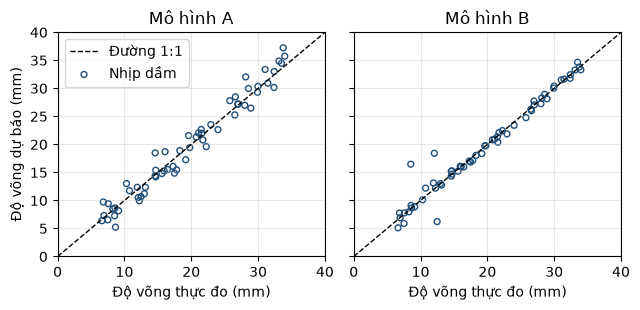

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(6.5, 3.2),
                        sharey=True)
for ax, yd, ten in zip(axs, [y_A, y_B], ["A", "B"]):
    ax.plot([0, 40], [0, 40], "k--", lw=1,
            label="Đường 1:1")
    ax.scatter(y_do, yd, s=18, marker="o",
               facecolors="none", edgecolors="#1f4e79",
               label="Nhịp dầm")
    ax.set_title(f"Mô hình {ten}")
    ax.set_xlabel("Độ võng thực đo (mm)")
    ax.set_xlim(0, 40); ax.set_ylim(0, 40)
    ax.grid(alpha=0.3)
axs[0].set_ylabel("Độ võng dự báo (mm)")
axs[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

### Chỉ số đánh giá mô hình phân loại

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,
    accuracy_score, recall_score, classification_report)

rng = np.random.default_rng(52)
n_ls, n_hh = 1900, 100      # 5 % mau hu hong
# do giam tan so rieng f1, f2 so voi trang thai goc (%)
X_ls = rng.normal([0.0, 0.0], [0.8, 0.8], (n_ls, 2))
X_hh = rng.normal([1.8, 1.2], [1.0, 1.0], (n_hh, 2))
Xc = np.vstack([X_ls, X_hh])
yc = np.r_[np.zeros(n_ls), np.ones(n_hh)].astype(int)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.3, stratify=yc, random_state=0)

# "mo hinh" ngay tho: luon ket luan cau lanh
y_ngaytho = np.zeros_like(yc_te)
print("Ngay tho: accuracy =",
      round(accuracy_score(yc_te, y_ngaytho), 3),
      "| recall =", recall_score(yc_te, y_ngaytho))

clf = LogisticRegression().fit(Xc_tr, yc_tr)
yc_du = clf.predict(Xc_te)
print("Ma tran nham lan [[TN FP] [FN TP]]:")
print(confusion_matrix(yc_te, yc_du))

Ngay tho: accuracy = 0.95 | recall = 0.0
Ma tran nham lan [[TN FP] [FN TP]]:
[[565   5]
 [ 12  18]]


In [4]:
print(classification_report(yc_te, yc_du, digits=3,
      target_names=["lanh (0)", "hu hong (1)"]))

              precision    recall  f1-score   support

    lanh (0)      0.979     0.991     0.985       570
 hu hong (1)      0.783     0.600     0.679        30

    accuracy                          0.972       600
   macro avg      0.881     0.796     0.832       600
weighted avg      0.969     0.972     0.970       600



### Đường ROC và lựa chọn ngưỡng quyết định

Nguong chon: 0.043
Tap kiem tra: recall = 0.867, precision = 0.245
TP=26, FN=4, FP=80, TN=490
AUC = 0.947, AP = 0.737


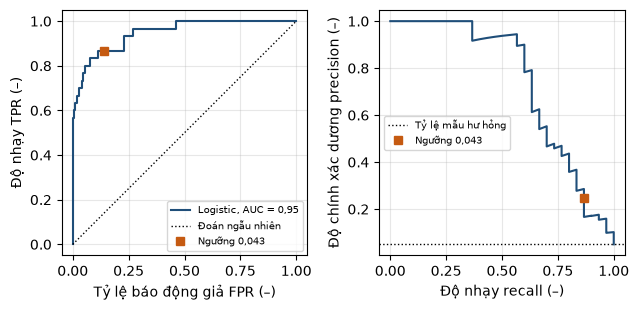

In [5]:
from sklearn.model_selection import (StratifiedKFold,
    cross_val_predict)
from sklearn.metrics import (roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    precision_score)

# xac suat ngoai mau cua tap huan luyen (5 lan chia)
skf5 = StratifiedKFold(n_splits=5, shuffle=True,
                       random_state=0)
p_oof = cross_val_predict(LogisticRegression(), Xc_tr, yc_tr,
                          cv=skf5, method="predict_proba")[:, 1]
p_te = clf.predict_proba(Xc_te)[:, 1]
# chon nguong tren p_oof: recall >= 0.90
fpr_h, tpr_h, ng_h = roc_curve(yc_tr, p_oof)
nguong = ng_h[np.argmax(tpr_h >= 0.90)]
y_ng = (p_te >= nguong).astype(int)
print(f"Nguong chon: {nguong:.3f}")
print(f"Tap kiem tra: recall = "
      f"{recall_score(yc_te, y_ng):.3f}, precision = "
      f"{precision_score(yc_te, y_ng):.3f}")
tn, fp, fn, tp = confusion_matrix(yc_te, y_ng).ravel()
print(f"TP={tp}, FN={fn}, FP={fp}, TN={tn}")
fpr, tpr, _ = roc_curve(yc_te, p_te)
pre, rec, _ = precision_recall_curve(yc_te, p_te)
auc = roc_auc_score(yc_te, p_te)
ap = average_precision_score(yc_te, p_te)
print(f"AUC = {auc:.3f}, AP = {ap:.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.5, 3.2))
a1.plot(fpr, tpr, "-", color="#1f4e79",
        label=f"Logistic, AUC = {auc:.2f}".replace(".", ","))
a1.plot([0, 1], [0, 1], "k:", lw=1, label="Đoán ngẫu nhiên")
nh = f"Ngưỡng {nguong:.3f}".replace(".", ",")
a1.plot(fp / (fp + tn), tp / (tp + fn), "s",
        color="#c55a11", label=nh)
a1.set_xlabel("Tỷ lệ báo động giả FPR (–)")
a1.set_ylabel("Độ nhạy TPR (–)")
a1.legend(loc="lower right", fontsize=7); a1.grid(alpha=0.3)
a2.plot(rec, pre, "-", color="#1f4e79")
a2.axhline(yc_te.mean(), color="k", ls=":", lw=1,
           label="Tỷ lệ mẫu hư hỏng")
a2.plot(tp / (tp + fn), tp / (tp + fp), "s",
        color="#c55a11", label=nh)
a2.set_xlabel("Độ nhạy recall (–)")
a2.set_ylabel("Độ chính xác dương precision (–)")
a2.legend(loc="center left", fontsize=7); a2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## KIỂM CHỨNG CHÉO, QUÁ KHỚP VÀ CHÍNH QUY HÓA

### Quá khớp và dưới khớp

bac  1: RMSE huan luyen =   17.2 mHz, kiem tra =    17.9 mHz
bac  2: RMSE huan luyen =   12.7 mHz, kiem tra =    14.5 mHz
bac  3: RMSE huan luyen =   10.5 mHz, kiem tra =    13.3 mHz
bac  4: RMSE huan luyen =   10.5 mHz, kiem tra =    13.3 mHz
bac  6: RMSE huan luyen =    9.3 mHz, kiem tra =    14.3 mHz
bac  8: RMSE huan luyen =    8.5 mHz, kiem tra =    15.8 mHz
bac 10: RMSE huan luyen =    7.9 mHz, kiem tra =    31.8 mHz
bac 12: RMSE huan luyen =    7.8 mHz, kiem tra =   101.1 mHz


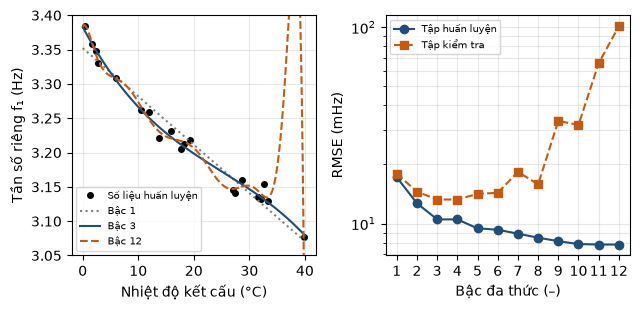

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (StandardScaler,
    PolynomialFeatures)
from sklearn.linear_model import LinearRegression, Ridge

def f_that(T):
    # tan so rieng f1 (Hz) theo nhiet do ket cau (do C)
    return (3.20 - 0.0055 * (T - 20)
            + 0.06 * np.exp(-(T - 2) / 5))

rng = np.random.default_rng(521)
T_tr = rng.uniform(0, 40, 20)
f_tr = f_that(T_tr) + rng.normal(0, 0.012, 20)
T_te = rng.uniform(0, 40, 300)
f_te = f_that(T_te) + rng.normal(0, 0.012, 300)

def da_thuc(d):
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(d),
                         LinearRegression())

def rmse(y, yd):
    return np.sqrt(np.mean((y - yd) ** 2))

bac = np.arange(1, 13)
e_tr, e_te = [], []
for d in bac:
    mh = da_thuc(d).fit(T_tr.reshape(-1, 1), f_tr)
    e_tr.append(1000 * rmse(f_tr, mh.predict(
        T_tr.reshape(-1, 1))))
    e_te.append(1000 * rmse(f_te, mh.predict(
        T_te.reshape(-1, 1))))
for d in [1, 2, 3, 4, 6, 8, 10, 12]:
    print(f"bac {d:2d}: RMSE huan luyen = {e_tr[d-1]:6.1f}"
          f" mHz, kiem tra = {e_te[d-1]:7.1f} mHz")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.5, 3.2))
Tl = np.linspace(0, 40, 300).reshape(-1, 1)
a1.plot(T_tr, f_tr, "ko", ms=4, label="Số liệu huấn luyện")
for d, ls, c in [(1, ":", "#7f7f7f"), (3, "-", "#1f4e79"),
                 (12, "--", "#c55a11")]:
    mh = da_thuc(d).fit(T_tr.reshape(-1, 1), f_tr)
    a1.plot(Tl, mh.predict(Tl), ls, color=c,
            label=f"Bậc {d}")
a1.set_ylim(3.05, 3.40)
a1.set_xlabel("Nhiệt độ kết cấu (°C)")
a1.set_ylabel("Tần số riêng f₁ (Hz)")
a1.legend(fontsize=7); a1.grid(alpha=0.3)
a2.semilogy(bac, e_tr, "o-", color="#1f4e79",
            label="Tập huấn luyện")
a2.semilogy(bac, e_te, "s--", color="#c55a11",
            label="Tập kiểm tra")
a2.set_xticks(bac)
a2.set_xlabel("Bậc đa thức (–)")
a2.set_ylabel("RMSE (mHz)")
a2.legend(fontsize=7); a2.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### Tập huấn luyện, tập kiểm định và kiểm chứng chéo k-fold

In [7]:
from sklearn.model_selection import (KFold,
    StratifiedKFold, TimeSeriesSplit, cross_val_score)

X1 = T_tr.reshape(-1, 1)
kf = KFold(n_splits=5, shuffle=True, random_state=0)
for d in [1, 3, 10]:
    s = -cross_val_score(da_thuc(d), X1, f_tr, cv=kf,
        scoring="neg_root_mean_squared_error")
    print(f"bac {d:2d}: RMSE kiem chung cheo = "
          f"{1000 * s.mean():.1f} +/- {1000 * s.std():.1f} mHz")

# so mau hu hong trong tung phan kiem dinh
skf = StratifiedKFold(n_splits=5, shuffle=True,
                      random_state=0)
print("KFold          :",
      [int(yc_tr[v].sum()) for _, v in kf.split(Xc_tr)])
print("StratifiedKFold:",
      [int(yc_tr[v].sum()) for _, v in
       skf.split(Xc_tr, yc_tr)])
s = cross_val_score(LogisticRegression(), Xc_tr, yc_tr,
                    cv=skf, scoring="f1")
print(f"F1 kiem chung cheo phan tang = "
      f"{s.mean():.3f} +/- {s.std():.3f}")

bac  1: RMSE kiem chung cheo = 16.4 +/- 7.4 mHz
bac  3: RMSE kiem chung cheo = 15.5 +/- 2.6 mHz
bac 10: RMSE kiem chung cheo = 422.8 +/- 717.6 mHz
KFold          : [13, 8, 20, 16, 13]
StratifiedKFold: [14, 14, 14, 14, 14]
F1 kiem chung cheo phan tang = 0.640 +/- 0.158


In [8]:
from sklearn.ensemble import RandomForestRegressor

rng = np.random.default_rng(522)
ngay = np.arange(730)
T_ng = (22 + 8 * np.sin(2 * np.pi * (ngay - 110) / 365)
        + rng.normal(0, 2, 730))
# f1 giam dan do suy giam do cung (khoang 2 % sau 2 nam)
f_ng = (3.20 - 0.0055 * (T_ng - 20) - 0.00009 * ngay
        + rng.normal(0, 0.008, 730))
X_ng = np.c_[T_ng, ngay]
rf = RandomForestRegressor(n_estimators=100,
                           random_state=0)
cach_chia = {"KFold xao tron": kf,
             "TimeSeriesSplit": TimeSeriesSplit(5)}
for ten, cv in cach_chia.items():
    s = -cross_val_score(rf, X_ng, f_ng, cv=cv,
        scoring="neg_root_mean_squared_error")
    print(f"{ten:16s}: RMSE = {1000 * s.mean():.1f} mHz")
for tr, kd in TimeSeriesSplit(5).split(X_ng):
    print(f"huan luyen ngay 0-{tr[-1]}, "
          f"kiem dinh ngay {kd[0]}-{kd[-1]}")

KFold xao tron  : RMSE = 9.2 mHz


TimeSeriesSplit : RMSE = 20.6 mHz
huan luyen ngay 0-124, kiem dinh ngay 125-245
huan luyen ngay 0-245, kiem dinh ngay 246-366
huan luyen ngay 0-366, kiem dinh ngay 367-487
huan luyen ngay 0-487, kiem dinh ngay 488-608
huan luyen ngay 0-608, kiem dinh ngay 609-729


### Chọn siêu tham số và chính quy hóa

In [9]:
from sklearn.model_selection import GridSearchCV

ridge10 = make_pipeline(StandardScaler(),
                        PolynomialFeatures(10),
                        StandardScaler(), Ridge())
luoi = {"ridge__alpha": [1e-3, 1e-2, 0.1, 1, 10]}
gs = GridSearchCV(ridge10, luoi, cv=kf,
                  scoring="neg_root_mean_squared_error")
gs.fit(X1, f_tr)
for a, s in zip(luoi["ridge__alpha"],
                gs.cv_results_["mean_test_score"]):
    print(f"alpha = {a:g}: RMSE kiem chung cheo = "
          f"{-1000 * s:.1f} mHz")
print("alpha chon:", gs.best_params_["ridge__alpha"])
e = rmse(f_te, gs.predict(T_te.reshape(-1, 1)))
print(f"RMSE tren tap kiem tra = {1000 * e:.1f} mHz")

alpha = 0.001: RMSE kiem chung cheo = 199.8 mHz
alpha = 0.01: RMSE kiem chung cheo = 112.0 mHz
alpha = 0.1: RMSE kiem chung cheo = 14.2 mHz
alpha = 1: RMSE kiem chung cheo = 37.4 mHz
alpha = 10: RMSE kiem chung cheo = 45.0 mHz
alpha chon: 0.1
RMSE tren tap kiem tra = 13.7 mHz


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve

cay = DecisionTreeClassifier(class_weight="balanced",
                             random_state=0)
sau = [1, 2, 3, 4, 6, 8, 12, 16]
s_tr, s_kd = validation_curve(cay, Xc_tr, yc_tr,
    param_name="max_depth", param_range=sau, cv=skf,
    scoring="roc_auc")
for d, a, b in zip(sau, s_tr.mean(1), s_kd.mean(1)):
    print(f"max_depth = {d:2d}: AUC huan luyen = {a:.3f}, "
          f"kiem dinh = {b:.3f}")
gs2 = GridSearchCV(cay, {"max_depth": sau}, cv=skf,
                   scoring="roc_auc").fit(Xc_tr, yc_tr)
print("max_depth chon:", gs2.best_params_["max_depth"])
print(f"AUC tren tap kiem tra = "
      f"{gs2.score(Xc_te, yc_te):.3f}")

max_depth =  1: AUC huan luyen = 0.883, kiem dinh = 0.857
max_depth =  2: AUC huan luyen = 0.932, kiem dinh = 0.879
max_depth =  3: AUC huan luyen = 0.963, kiem dinh = 0.915
max_depth =  4: AUC huan luyen = 0.979, kiem dinh = 0.897
max_depth =  6: AUC huan luyen = 0.992, kiem dinh = 0.799
max_depth =  8: AUC huan luyen = 0.998, kiem dinh = 0.740
max_depth = 12: AUC huan luyen = 1.000, kiem dinh = 0.723
max_depth = 16: AUC huan luyen = 1.000, kiem dinh = 0.724


max_depth chon: 3
AUC tren tap kiem tra = 0.896


## DIỄN GIẢI MÔ HÌNH VÀ KHUYẾN NGHỊ KỸ THUẬT

### Hệ số của mô hình tuyến tính

In [11]:
rng = np.random.default_rng(531)
n = 80
L = rng.uniform(24, 40, n)              # nhip (m)
h = L / 17 + rng.normal(0, 0.04, n)     # chieu cao dam (m)
tuoi = rng.uniform(3, 45, n)            # tuoi cau (nam)
fc = rng.uniform(30, 50, n)             # cuong do BT (MPa)

def dv_that(L, h, tuoi, fc):
    # do vong (mm) ~ L^4 / (E h^3), E ~ sqrt(fc)
    suy = 1 + 0.004 * tuoi + 0.02 * np.maximum(tuoi - 25, 0)
    return (14.0 * (L / 32) ** 4 * (32 / 17 / h) ** 3
            * np.sqrt(40 / fc) * suy)

dv = dv_that(L, h, tuoi, fc) * rng.normal(1, 0.03, n)
Xd = pd.DataFrame({"L": L, "h": h, "tuoi": tuoi, "fc": fc})
Xs = (Xd - Xd.mean()) / Xd.std()
m4 = LinearRegression().fit(Xs, dv)
m3 = LinearRegression().fit(Xs.drop(columns="h"), dv)
# he so phong dai phuong sai VIF (muc 3.1)
vif = []
for c in Xd.columns:
    khac = Xs.drop(columns=c)
    r2 = LinearRegression().fit(khac, Xs[c]).score(khac, Xs[c])
    vif.append(1 / (1 - r2))
hs = pd.DataFrame({"He so du 4 bien": m4.coef_,
                   "VIF": vif}, index=Xd.columns)
hs.loc[["L", "tuoi", "fc"], "He so bo h"] = m3.coef_
print("He so (mm / 1 do lech chuan):")
print(hs.round(2))

He so (mm / 1 do lech chuan):
      He so du 4 bien    VIF  He so bo h
L               10.43  71.50        2.57
h               -7.92  71.61         NaN
tuoi             2.28   1.01        2.27
fc              -1.15   1.03       -1.20


### Mức độ quan trọng của biến

So cau theo cap 1-4: [66, 140, 204, 190]


Accuracy tap kiem tra = 0.717


         Gini  Hoan vi  Hoan vi (std)
tuoi    0.386    0.348          0.033
xe_tai  0.259    0.233          0.030
bien    0.175    0.075          0.017
loai    0.055    0.013          0.014
nhieu   0.126   -0.008          0.015


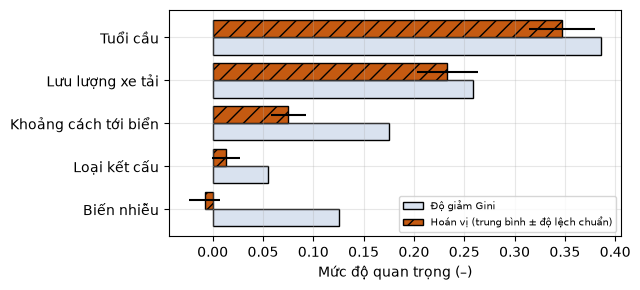

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(532)
n = 600
dl = pd.DataFrame({
    "tuoi": rng.uniform(2, 60, n),          # nam
    "xe_tai": rng.uniform(200, 6000, n),    # xe/ngay dem
    "bien": rng.uniform(0.5, 80, n),        # km toi bien
    "loai": rng.integers(0, 3, n),   # 0 BTCT, 1 BTDUL, 2 thep
    "nhieu": rng.normal(0, 1, n)})   # bien ngau nhien
diem = (0.05 * dl.tuoi + 0.0003 * dl.xe_tai
        + 1.5 * np.exp(-dl.bien / 15) + 0.4 * (dl.loai == 2)
        + rng.normal(0, 0.4, n))
dl["cap"] = pd.cut(diem, [-9, 1.5, 2.5, 3.5, 99],
                   labels=[1, 2, 3, 4]).astype(int)
print("So cau theo cap 1-4:",
      dl.cap.value_counts().sort_index().tolist())
bien_x = ["tuoi", "xe_tai", "bien", "loai", "nhieu"]
Xq_tr, Xq_te, yq_tr, yq_te = train_test_split(
    dl[bien_x], dl.cap, test_size=0.3, random_state=0,
    stratify=dl.cap)
rfc = RandomForestClassifier(n_estimators=300,
                             random_state=0).fit(Xq_tr, yq_tr)
print(f"Accuracy tap kiem tra = {rfc.score(Xq_te, yq_te):.3f}")
pi = permutation_importance(rfc, Xq_te, yq_te, n_repeats=20,
                            random_state=0)
qt = pd.DataFrame({"Gini": rfc.feature_importances_,
                   "Hoan vi": pi.importances_mean,
                   "Hoan vi (std)": pi.importances_std},
                  index=bien_x)
print(qt.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.0))
vt = np.arange(len(bien_x))
ax.barh(vt + 0.2, qt["Gini"], 0.4, color="#d9e2ef",
        edgecolor="k", label="Độ giảm Gini")
ax.barh(vt - 0.2, qt["Hoan vi"], 0.4, color="#c55a11",
        edgecolor="k", hatch="//", xerr=qt["Hoan vi (std)"],
        label="Hoán vị (trung bình ± độ lệch chuẩn)")
ax.set_yticks(vt)
ax.set_yticklabels(["Tuổi cầu", "Lưu lượng xe tải",
                    "Khoảng cách tới biển", "Loại kết cấu",
                    "Biến nhiễu"])
ax.invert_yaxis()
ax.set_xlabel("Mức độ quan trọng (–)")
ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Phân tích phần dư và giới hạn áp dụng

RMSE = 1.06 mm, R2 = 0.918


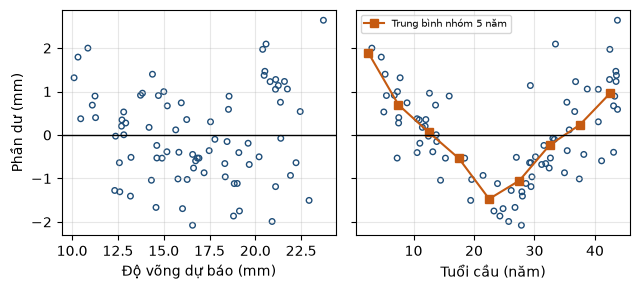

In [13]:
mh_d = LinearRegression().fit(Xd, dv)
dv_du = mh_d.predict(Xd)
pd_d = dv - dv_du
print(f"RMSE = {rmse(dv, dv_du):.2f} mm, "
      f"R2 = {r2_score(dv, dv_du):.3f}")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.5, 3.0),
                             sharey=True)
a1.scatter(dv_du, pd_d, s=16, facecolors="none",
           edgecolors="#1f4e79")
a1.set_xlabel("Độ võng dự báo (mm)")
a1.set_ylabel("Phần dư (mm)")
a2.scatter(Xd.tuoi, pd_d, s=16, facecolors="none",
           edgecolors="#1f4e79")
nhom = pd.cut(Xd.tuoi, np.arange(0, 50, 5))
tb = pd.Series(pd_d).groupby(nhom, observed=True).mean()
a2.plot([iv.mid for iv in tb.index], tb.values, "s-",
        color="#c55a11", label="Trung bình nhóm 5 năm")
a2.legend(fontsize=7, loc="upper left")
a2.set_xlabel("Tuổi cầu (năm)")
for a in (a1, a2):
    a.axhline(0, color="k", lw=1); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# kiem tra mien du lieu truoc khi du bao cho cau moi
moi = pd.DataFrame({"L": [33.0, 48.0, 33.0],
                    "h": [1.95, 2.80, 1.95],
                    "tuoi": [20.0, 20.0, 60.0],
                    "fc": [40.0, 40.0, 40.0]})
ngoai = (moi < Xd.min()) | (moi > Xd.max())
du = mh_d.predict(moi)
that = dv_that(moi.L, moi.h, moi.tuoi, moi.fc)
for i in range(len(moi)):
    print(f"Cau {i + 1}: du bao = {du[i]:.1f} mm, "
          f"mo phong = {that[i]:.1f} mm, ngoai mien: "
          f"{list(moi.columns[ngoai.iloc[i]])}")

Cau 1: du bao = 16.5 mm, mo phong = 15.4 mm, ngoai mien: []
Cau 2: du bao = 25.0 mm, mo phong = 23.3 mm, ngoai mien: ['L', 'h']
Cau 3: du bao = 23.7 mm, mo phong = 27.6 mm, ngoai mien: ['tuoi']


### Từ kết quả mô hình đến khuyến nghị kỹ thuật

## BÁO CÁO KẾT QUẢ PHÂN TÍCH DỮ LIỆU

### Cấu trúc báo cáo và trình bày kết quả

In [15]:
import sys, sklearn
print("Python", sys.version.split()[0], "| numpy",
      np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
# khoang tin cay 95 % cua RMSE mo hinh A bang bootstrap
rng = np.random.default_rng(541)
e_A = y_A - y_do
bs = [np.sqrt(np.mean(rng.choice(e_A, len(e_A)) ** 2))
      for _ in range(2000)]
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"RMSE mo hinh A = {rmse(y_do, y_A):.2f} mm, "
      f"KTC 95 %: [{lo:.2f}; {hi:.2f}] mm")

Python 3.12.9 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
RMSE mo hinh A = 1.70 mm, KTC 95 %: [1.43; 1.96] mm


### Quản lý và lưu trữ mã nguồn nghiên cứu

*Cây thư mục dự án, không phải mã lệnh.*

```
du_an_do_vong_cau/
├── README.md          # muc dich, nguon du lieu, cach chay
├── requirements.txt   # phien ban thu vien
├── .gitignore         # tep Git khong theo doi
├── du_lieu/
│   ├── goc/           # du lieu goc: chi doc, khong sua
│   │   ├── quan_trac_2026.csv
│   │   └── thi_nghiem_vat_lieu.xlsx
│   └── da_xu_ly/      # sinh ra tu ma, xoa va tao lai duoc
├── ma_nguon/
│   ├── doc_va_lam_sach.py
│   ├── mo_hinh.py
│   └── ve_hinh.py
├── notebook/
│   └── phan_tich.ipynb
├── ket_qua/
│   ├── bang/          # bang so lieu do ma sinh ra
│   └── hinh/          # hinh do ma sinh ra
└── bao_cao/
    └── bao_cao.docx
```

In [16]:
# tinh_do_vong.py
# Muc dich: tinh do vong chuan hoa ve tai trong 300 kN
#           va nhiet do 20 do C (muc 3.3.2)
# Don vi  : tai trong kN, do vong mm, nhiet do do C
# Vao     : du_lieu/goc/quan_trac_2026.csv
# Ra      : ket_qua/bang/do_vong_chuan_hoa.csv
#           ket_qua/hinh/phan_du_theo_ngay.png

*Nội dung tệp requirements.txt.*

```
# requirements.txt (Python 3.12.9)
numpy==2.5.4
pandas==3.0.6
scipy==1.18.1
scikit-learn==1.9.1
matplotlib==3.11.2

# lenh tao tep va cai lai moi truong
pip freeze > requirements.txt
pip install -r requirements.txt
```

In [17]:
import numpy as np
from sklearn.model_selection import train_test_split

# cung hat giong -> cung day so ngau nhien
a = np.random.default_rng(42).normal(30, 5, 3)
b = np.random.default_rng(42).normal(30, 5, 3)
print("Lan 1:", a.round(2))
print("Lan 2:", b.round(2))
print("Hai day giong nhau:", np.array_equal(a, b))
# cung random_state -> cung cach chia tap (10 mau)
chi_so = np.arange(10)
for lan in (1, 2):
    hl, kt = train_test_split(chi_so, test_size=0.3,
                              random_state=0)
    print(f"Lan {lan}: tap kiem tra = {kt}")

Lan 1: [31.52 24.8  33.75]
Lan 2: [31.52 24.8  33.75]
Hai day giong nhau: True
Lan 1: tap kiem tra = [2 8 4]
Lan 2: tap kiem tra = [2 8 4]


*Minh họa xung đột khi hợp nhất nhánh Git.*

```
<<<<<<< HEAD
CI_NG = 60     # nguong sua chua (nhanh chinh)
=======
CI_NG = 55     # nguong sua chua (nhanh thu_nguong)
>>>>>>> thu_nguong
```

*Nội dung tệp .gitignore.*

```
# .gitignore - cac tep va thu muc Git khong theo doi
__pycache__/
.ipynb_checkpoints/
.venv/
du_lieu/da_xu_ly/        # sinh lai bang ma
ket_qua/                 # sinh lai bang ma
du_lieu/goc/gia_toc_*/   # tep gia toc dung luong lon
*.tmp
```

## BÀI TẬP